In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [2]:
%pip install langchain langchain-core langchain-openai langchain-anthropic -q

import os
if os.path.exists("requirements.txt"):
    %pip install -r requirements.txt -q
else:
    print("⚠️  requirements.txt not found — skipping")


Note: you may need to restart the kernel to use updated packages.
⚠️  requirements.txt not found — skipping


In [3]:
%pip install langchain-ollama -q

Note: you may need to restart the kernel to use updated packages.


In [4]:
%pip install yfinance bdshare -q


Note: you may need to restart the kernel to use updated packages.


In [ ]:
# ======================================================================
# COMPANY PROFILE -- the only company-specific part of this notebook.
# The analysts, debate, trader, risk and verifier code is shared by every dse notebook: raem_analysts/dse/
# To change a company-specific value (ticker, log name, peer list, sector text), edit it here.
# ======================================================================
COMPANY = "ABBANK"
RAEM_PROFILE = {
    "group": "dse",
    "TICKER": "ABBANK",
    "LOG": "ABBANK",
    "FILE": "ABBANK",
    "slots": {
        "llm_setup_and_logger.1": [
            "    \"ABBANK\": \"Sector: Financials (Banks) | Exchange: Dhaka Stock Exchange (DSE)\","
        ],
        "news_analyst.1": [
            "def fetch_web_news_for_company(ticker: str, company_hint: str = \"AB Bank Limited\", max_results: int = 8) -> str:"
        ]
    }
}

import os, sys
sys.path.insert(0, os.getcwd())   # raem_analysts/ sits next to the notebooks
from raem_analysts import use_shared

In [ ]:
# Llm Setup And Logger -- shared code: raem_analysts/dse/llm_setup_and_logger.py
use_shared("llm_setup_and_logger")

In [6]:
import sys, os

# TradingAgents is vendored next to this folder, in ../TradingAgents-main.
# To use a checkout somewhere else, set the TRADINGAGENTS_PATH environment
# variable before starting Jupyter -- it is tried first.
_candidates = [
    os.environ.get("TRADINGAGENTS_PATH", ""),
    os.path.abspath(os.path.join(os.getcwd(), "..", "TradingAgents-main")),
    os.path.abspath(os.path.join(os.getcwd(), "TradingAgents-main")),
    os.path.abspath(os.path.join(os.getcwd(), "TradingAgents")),
]
TRADING_AGENTS_PATH = next(
    (p for p in _candidates if p and os.path.isdir(os.path.join(p, "tradingagents"))),
    _candidates[1],
)

if TRADING_AGENTS_PATH not in sys.path:
    sys.path.insert(0, TRADING_AGENTS_PATH)

if not os.path.isdir(os.path.join(TRADING_AGENTS_PATH, "tradingagents")):
    print(f"⚠️  TradingAgents not found at: {TRADING_AGENTS_PATH}")
    print("    Set the TRADINGAGENTS_PATH environment variable to your TradingAgents checkout.")
else:
    print("✅ Path added:", TRADING_AGENTS_PATH)


✅ Path added: C:\Users\Capstone_Project\Downloads\TradingAgents-main


## DSE (Dhaka Stock Exchange) Data Source Layer

Replaces the Finnhub/yfinance-backed tools from the `tradingagents` package
(`get_stock_data`, `get_indicators`, `get_fundamentals`, `get_balance_sheet`,
`get_cashflow`, `get_income_statement`, `get_news`, `get_global_news`) with
versions that pull real data for DSE-listed tickers (e.g. **ABBANK**) from
DSE's public website (dsebd.org).

DSE has no official public API like Finnhub, so this scrapes DSE's public
HTML pages. If dsebd.org changes its page layout, the parsing in
`fetch_dse_ohlcv_range` / `fetch_dse_company_snapshot` / `fetch_dse_news`
below is the first place to fix. Full balance sheet / cash flow / income
statement line items aren't published on DSE's public site (only in annual
report PDFs), so those three tools return an explicit "not available"
message instead of guessing -- the existing prompts already handle "data
not available" gracefully.

In [ ]:
# Dse Data Source Layer -- shared code: raem_analysts/dse/dse_data_source_layer.py
use_shared("dse_data_source_layer")

In [ ]:
# Dse Endpoint Probe -- shared code: raem_analysts/dse/dse_endpoint_probe.py
use_shared("dse_endpoint_probe")

## 🧠 ChromaDB Memory Setup (RAEM Episodic Memory + News RAG)

In [8]:
%pip install chromadb -q


Note: you may need to restart the kernel to use updated packages.


In [9]:
# Chromadb Memory Setup -- shared code: raem_analysts/dse/chromadb_memory_setup.py
use_shared("chromadb_memory_setup")

✅ ChromaDB ready at: ./raem_chroma_db
   📦 episodic_memory  : 11 episodes stored
   📰 news_corpus      : 103 chunks stored
✅ Regime classifier + ID helper ready!


## 📈 Outcome Backfill — পুরোনো PENDING episodes-এ আজকের price দিয়ে P&L আপডেট

In [10]:
# Outcome Backfill -- shared code: raem_analysts/dse/outcome_backfill.py
use_shared("outcome_backfill")

📈 OUTCOME BACKFILL — পুরোনো episode-এ P&L আপডেট
   ℹ️  কোনো PENDING episode নেই — backfill করার কিছু নেই।
   মোট resolve হলো: 0 episode



In [11]:
import os
os.environ["TRADINGAGENTS_LLM_PROVIDER"] = "ollama"
print("✅ Config ready!")

✅ Config ready!


## 🛡️ Fact Guard — handoff-level hallucination check on every LLM call

Each agent's output is checked in code before the next agent reads it: numbers must come from the agent's own input, and known label/direction errors (SMA support vs resistance, N/A cited as 0%, TTM mislabel, missing data read as neutral) trigger one re-ask. Set `GUARD_ENABLED = False` to turn it off.

In [ ]:
# Fact Guard -- shared code: raem_analysts/dse/fact_guard.py
use_shared("fact_guard")

In [ ]:
# Fundamentals Analyst -- shared code: raem_analysts/dse/fundamentals_analyst.py
use_shared("fundamentals_analyst")

In [ ]:
# Market Analyst -- shared code: raem_analysts/dse/market_analyst.py
use_shared("market_analyst")

## 🌍 Macro Regime Analyst — DSE-Adapted Market-Wide Risk Regime (DSEX realized vol / DSEX trend / USD-BDT)


In [ ]:
# Macro Regime Analyst -- shared code: raem_analysts/dse/macro_regime_analyst.py
use_shared("macro_regime_analyst")

In [ ]:
# News Analyst -- shared code: raem_analysts/dse/news_analyst.py
use_shared("news_analyst")

## 📰 News RAG — Chunk & Store in ChromaDB

In [ ]:
# News Rag -- shared code: raem_analysts/dse/news_rag.py
use_shared("news_rag")

In [ ]:
# Sentiment Analyst -- shared code: raem_analysts/dse/sentiment_analyst.py
use_shared("sentiment_analyst")

## 🕸️ Graph Analyst — DSE Peer Graph + GAT (adapted from BlindTrade)

Builds a sector + correlation graph over DSE peers, computes neighbor-aggregated features for the target stock, and trains a small GAT walk-forward. The GAT score is passed to the debaters **only if its holdout rank-IC > 0** (validate-before-deploy). Output `graph_context` is picked up by `format_hard_indicators()` in the next cell.

In [ ]:
# Graph Analyst -- shared code: raem_analysts/dse/graph_analyst.py
use_shared("graph_analyst")

## 🕸️ Graph-linked news + peer-graph retrieval
Rule-based knowledge graph over `news_corpus` (NEWS → TICKER / TOPIC / REG edges). Uses `graph_result` peers, adds sector/regulator news (tobacco tax, NBR) and peers' notices to `news_rag_context`. Switch: `USE_NEWS_GRAPH`.


## 👥🧬 Graph-RAG extensions (v4)
Two cells run **before** the news-graph cell: (1) peer-stock price episodes (regime → forward return) stored in `episodic_memory`, so the peer-episode hop has data; (2) LLM entity/relation extraction (Qwen2.5:7b, JSON mode, grounded in code, disk-cached) that adds entity/relation edges to the news graph. Ablation switches: `USE_PEER_EPISODES`, `USE_LLM_GRAPH`.

In [ ]:
# Peer Episodes -- shared code: raem_analysts/dse/peer_episodes.py
use_shared("peer_episodes")

In [ ]:
# Llm Graph Extraction -- shared code: raem_analysts/dse/llm_graph_extraction.py
use_shared("llm_graph_extraction")

In [ ]:
# Graph News -- shared code: raem_analysts/dse/graph_news.py
use_shared("graph_news")

## 🔮 Forecasting Agent (validated 10-day price forecast)

Code-only agent: purged walk-forward validation of naive / damped-trend / ridge / analog-kNN. A model is used only if it beats the naive baseline on a holdout (MAE, t-stat, direction gate); otherwise the agent reports **no forecast skill** and only a historical-error range. Result is injected into the FACT SHEET and logged to `forecast_log/ABBANK_forecasts.csv` (same schema as the other forecast logs).

In [ ]:
# Forecasting Agent -- shared code: raem_analysts/dse/forecasting_agent.py
use_shared("forecasting_agent")

In [ ]:
# Hard Data Helper -- shared code: raem_analysts/dse/hard_data_helper.py
use_shared("hard_data_helper")

In [ ]:
# Bear Researcher -- shared code: raem_analysts/dse/bear_researcher.py
use_shared("bear_researcher")

In [ ]:
# Bull Researcher -- shared code: raem_analysts/dse/bull_researcher.py
use_shared("bull_researcher")

In [ ]:
# Investment Facilitator -- shared code: raem_analysts/dse/investment_facilitator.py
use_shared("investment_facilitator")

In [22]:
# Investment Debate Facilitator -- shared code: raem_analysts/dse/investment_debate_facilitator.py
use_shared("investment_debate_facilitator")

⚖️  INVESTMENT DEBATE FACILITATOR DECISION
### Scoring Rubric

1. **Bull Evidence Count**: 
   - **RSI and MACD**: The RSI is in the oversold range (45.4545), and the MACD is negative (-0.0730).
   - **50-day SMA and Bollinger Bands**: The stock price is within the Bollinger Bands and not breaking below the 50-day SMA (4.7480).
   - **Fundamental Strengths**: The company's financial performance, market position, and regulatory environment provide significant potential for growth.
   - **Growth Opportunities**: The company's digital transformation and favorable regulatory environment can enhance its customer experience and operational efficiency.
   - **Regulatory Environment**: The government's policies on financial inclusion and digital banking support the company's growth.

   **bull_evidence_count = 4**

2. **Bear Evidence Count**:
   - **RSI and MACD**: The RSI is at 45.45, indicating a neutral to slightly oversold condition, and the MACD is negative (-0.0730).
   - **50-day SMA an

## 🔁 Retrieve Similar Past Episodes (for Trader memory injection)

## 🔄 Regime-Transition Reflection — regime বদলালে আগের regime থেকে শেখা

In [ ]:
# Regime Transition Reflection -- shared code: raem_analysts/dse/regime_transition_reflection.py
use_shared("regime_transition_reflection")

## 🧾 Post-Mortem / Self-Critique Agent — Cross-Regime Lessons Learned

In [ ]:
# Post Mortem Agent -- shared code: raem_analysts/dse/post_mortem_agent.py
use_shared("post_mortem_agent")

## 🕸️ Graph Memory — graph-RAG over episodic memory


In [ ]:
# Graph Memory -- shared code: raem_analysts/dse/graph_memory.py
use_shared("graph_memory")

In [ ]:
# Retrieve Past Episodes -- shared code: raem_analysts/dse/retrieve_past_episodes.py
use_shared("retrieve_past_episodes")

In [ ]:
# Trader -- shared code: raem_analysts/dse/trader.py
use_shared("trader")

In [ ]:
# Aggressive Debator -- shared code: raem_analysts/dse/aggressive_debator.py
use_shared("aggressive_debator")

In [ ]:
# Conservative Debator -- shared code: raem_analysts/dse/conservative_debator.py
use_shared("conservative_debator")

In [ ]:
# Neutral Debator -- shared code: raem_analysts/dse/neutral_debator.py
use_shared("neutral_debator")

In [ ]:
# Risk Debate -- shared code: raem_analysts/dse/risk_debate.py
use_shared("risk_debate")

In [ ]:
# Risk Facilitator -- shared code: raem_analysts/dse/risk_facilitator.py
use_shared("risk_facilitator")

In [ ]:
# Portfolio Manager -- shared code: raem_analysts/dse/portfolio_manager.py
use_shared("portfolio_manager")

In [ ]:
# Portfolio Manager Decision -- shared code: raem_analysts/dse/portfolio_manager_decision.py
use_shared("portfolio_manager_decision")

## 📈 Prediction Engine — Quantitative 5-Day Price Forecast


In [ ]:
# Prediction Engine -- shared code: raem_analysts/dse/prediction_engine.py
use_shared("prediction_engine")

In [ ]:
# Forecast Graph -- shared code: raem_analysts/dse/forecast_graph.py
use_shared("forecast_graph")

## 🔍 Decision Verifier / Fact-Check Agent — Post-Decision Recheck

In [ ]:
# Decision Verifier -- shared code: raem_analysts/dse/decision_verifier.py
use_shared("decision_verifier")

## 📈 10-Day Scenario Estimate — if you buy today, what range of gain/loss could 10 trading days bring?

For every day in the last 12 months of DSE closes: `10-day return % = (close 10 trading days later / close that day − 1) × 100`. The percentiles of those ~230 returns (worst 5% … best 5%) are applied to your buy price, with an assumed round-trip cost, and the chance of a gain is counted.

Set `SCEN_BUY_PRICE`, `SCEN_SHARES` and `SCEN_COST_PCT` at the top of the next cell. It is the **historical range** of outcomes, **not a forecast** and not investment advice. Skips quietly if the DSE fetch fails.

In [ ]:
# Scenario Estimate -- shared code: raem_analysts/dse/scenario_estimate.py
use_shared("scenario_estimate")

## 💾 Save Episode to ChromaDB Memory

In [ ]:
# Save Episode -- shared code: raem_analysts/dse/save_episode.py
use_shared("save_episode")

In [36]:
# Trading Log View -- shared code: raem_analysts/dse/trading_log_view.py
use_shared("trading_log_view")

📦 Total sessions in file: 18
📅 Showing: 2026-09-27 (most recent)

Session start : 2026-09-27 14:41:13
Company       : ABBANK
Total steps   : 14

⏰ 14:41:14 | 📌 LLM Setup
----------------------------------------------------------------------
📥 INPUT:
Ollama Qwen2.5 7B

📤 OUTPUT:
LLM initialized

⏰ 14:41:36 | 📌 Fundamentals Analyst
----------------------------------------------------------------------
📥 INPUT:
  [COMPANY]: ABBANK
  [DATE]: 2026-09-27
  [TOOLS_USED]: get_fundamentals, get_balance_sheet, get_cashflow, get_income_statement

📤 OUTPUT:
  [METRICS]: {'market_cap': '৳4.03B', 'pe_ratio': 'N/A', 'eps_ttm': '-12.41', 'revenue_ttm': 'N/A', 'beta': 'N/A', 'dividend_yield': 'N/A', '52w_high': '7.70', '52w_low': '3.40', 'sector': 'Bank', 'last_trading_price': '4.40', 'net_income_q': '৳-11.12B', 'gross_profit_q': 'N/A', 'operating_income_q': 'N/A', 'ebitda_q': 'N/A', 'cash_dividend': '2% 2021, 5% 2013, 5% 2011, 10% 2010', 'bonus_issue': '2% 2023, 2% 2022, 3% 2021, 5% 2020, 5% 2019, 12.

In [37]:
# Comparison Backtest -- shared code: raem_analysts/dse/comparison_backtest.py
use_shared("comparison_backtest")

✅ Loaded 18 sessions

📋 DAILY DECISION COMPARISON


'      Date Company Decision                                                                                                                  Summary\n2026-09-22  ABBANK      N/A                                                                                                                         \n2026-09-22  ABBANK      N/A                                                                                                                         \n2026-09-22  ABBANK      N/A                                                                                                                         \n2026-09-22  ABBANK      N/A                                                                                                                         \n2026-09-24  ABBANK      N/A                                                                                                                         \n2026-09-24  ABBANK      N/A                                                                        


📈 TECHNICAL INDICATOR TRENDS


'      Date       RSI      MACD   50-SMA   Boll_UB   Boll_LB\n2026-09-22       NaN       NaN      NaN       NaN       NaN\n2026-09-22       NaN       NaN      NaN       NaN       NaN\n2026-09-22       NaN       NaN      NaN       NaN       NaN\n2026-09-22       NaN       NaN      NaN       NaN       NaN\n2026-09-24       NaN       NaN      NaN       NaN       NaN\n2026-09-24       NaN       NaN      NaN       NaN       NaN\n2026-09-24       NaN       NaN      NaN       NaN       NaN\n2026-09-24       NaN       NaN      NaN       NaN       NaN\n2026-09-24       NaN       NaN      NaN       NaN       NaN\n2026-09-24       NaN       NaN      NaN       NaN       NaN\n2026-09-24 2026.0000 2026.0000 2026.000 2026.0000 2026.0000\n2026-09-24 2026.0000 2026.0000 2026.000 2026.0000 2026.0000\n2026-09-24 2026.0000 2026.0000 2026.000 2026.0000 2026.0000\n2026-09-24   45.4545   -0.0714    4.766    4.7742    4.3158\n2026-09-27       NaN       NaN      NaN       NaN       NaN\n2026-09-27       NaN   


🏦 FUNDAMENTALS TRACKING


...


📰 NEWS SENTIMENT TREND


'      Date Overall Positive Negative Neutral\n2026-09-22     N/A      N/A      N/A     N/A\n2026-09-22     N/A      N/A      N/A     N/A\n2026-09-22     N/A      N/A      N/A     N/A\n2026-09-22     N/A      N/A      N/A     N/A\n2026-09-24     N/A      N/A      N/A     N/A\n2026-09-24     N/A      N/A      N/A     N/A\n2026-09-24     N/A      N/A      N/A     N/A\n2026-09-24     N/A      N/A      N/A     N/A\n2026-09-24     N/A      N/A      N/A     N/A\n2026-09-24     N/A      N/A      N/A     N/A\n2026-09-24 NEUTRAL        1        1       6\n2026-09-24 NEUTRAL        1        1       6\n2026-09-24 NEUTRAL        0        0       8\n2026-09-24 NEUTRAL        0        0       4\n2026-09-27     N/A      N/A      N/A     N/A\n2026-09-27     N/A      N/A      N/A     N/A\n2026-09-27     N/A      N/A      N/A     N/A\n2026-09-27 NEUTRAL        0        0       9'


💰 SIMPLE BACKTEST — Follow-the-Signal Strategy


'      Date Signal Price Action Portfolio\n2026-09-22   HOLD   N/A      —   $10,000\n2026-09-22   HOLD   N/A      —   $10,000\n2026-09-22   HOLD   N/A      —   $10,000\n2026-09-22   HOLD   N/A      —   $10,000\n2026-09-24   HOLD   N/A      —   $10,000\n2026-09-24   HOLD   N/A      —   $10,000\n2026-09-24   HOLD   N/A      —   $10,000\n2026-09-24   HOLD   N/A      —   $10,000\n2026-09-24   HOLD   N/A      —   $10,000\n2026-09-24   HOLD   N/A      —   $10,000\n2026-09-24   HOLD   N/A      —   $10,000\n2026-09-24   HOLD   N/A      —   $10,000\n2026-09-24   HOLD   N/A      —   $10,000\n2026-09-24   SELL $4.50      —   $10,000\n2026-09-27   HOLD   N/A      —   $10,000\n2026-09-27   HOLD   N/A      —   $10,000\n2026-09-27   HOLD   N/A      —   $10,000\n2026-09-27   HOLD $4.40      —   $10,000'


  Starting Capital : $10,000
  Final Value      : $10,000
  Total Return     : +0.00%

🎯 DECISION CONSISTENCY
  SELL   █  (1/2 days — 50%)
  HOLD   █  (1/2 days — 50%)

✅ Analysis complete!


## 📈 7-Day Forecast & Hit Rate (standalone)

This section runs **on its own**: no Ollama and none of the agent cells above are needed. After a kernel restart you can run just the cell below.

It trains 14 base models:

- **Originals:** Ridge, XGBoost, LSTM, ARIMA, Kalman.
- **From the papers in `paper/`:** LASSO (Iworiso 2023), Random Forest and DNN (Krauss et al. 2016), WSAE-LSTM (Bao et al. 2017), N-BEATS (Oreshkin et al. 2020).
- **Also added:** regime switching, ARIMAX, a Temporal Fusion Transformer (TFT), and the Theta method.

On top of these sit two **fusion** models, which learn for this ticker how to combine the base models:

- **Fusion:** learned non-negative weights, with "no change" as one of the options.
- **Fusion-Top3:** the 3 lowest-error models, each weighted by 1/error.

The **Ensemble** is the average of the **best two** base models for this ticker, meaning the two with the lowest error on past holdout dates. The main chart draws **every** model's path. A second chart gives each model its own panel, and the table lists every model's forecast and its error against "no change".

During **Run All**, this cell reuses the forecast already trained by the *7-DAY FORECAST GRAPH* cell above instead of training everything twice.

**Fusion check table:** this is the fair comparison. Each pick (best two, fusion weights, top 3) is made on the earlier holdout dates. Then every model, the Ensemble, both fusions, the mean of all models and "no change" are scored on later dates that the picks never saw. A `mae_vs_naive` below 1 beats "no change".

Every run saves today's 7-day forecast to `forecast_log/`. It then grades every earlier forecast whose target date has arrived. The **hit rate** is measured two ways:

- **Within ±1%**: the predicted price landed within 1% of the actual close on that day.
- **Direction right**: the forecast said up or down from the price when it was made, and the price went that way. "No change" forecasts don't count either way.

A direction hit rate only means something if it beats **always predicting UP**, because stocks drift, so that baseline is shown next to it. The **p-value** says whether the day-7 calls beat a coin flip by more than luck; under 0.05 means they do. Past forecasts include walk-forward replays, each trained only on data available on that date.

  ABBANK: not a yfinance-format CSV -- skipping top-up
ABBANK (AB Bank): 478 rows (476 snapshot + 2 daily-log), 2024-09-19 to 2026-09-27
  training 14 multi-step models on 422 labeled rows ...


Graded 0 past prediction(s) whose target date has now arrived.


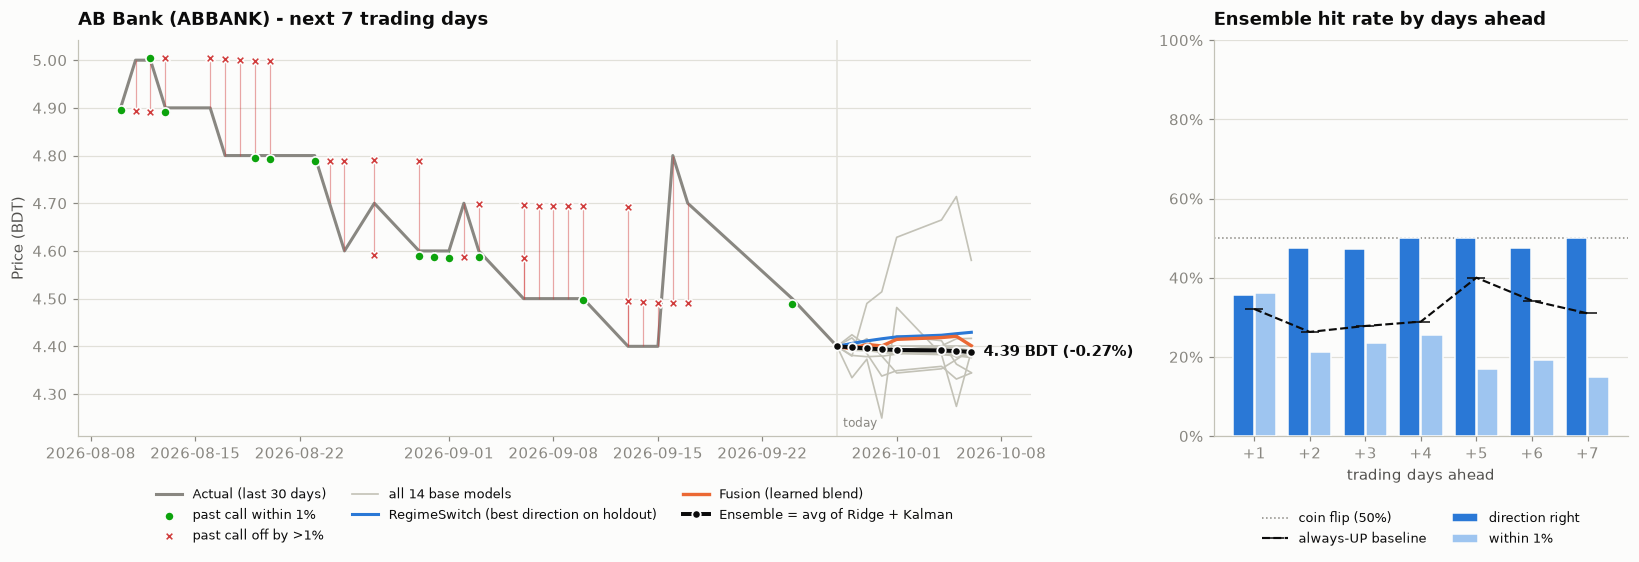

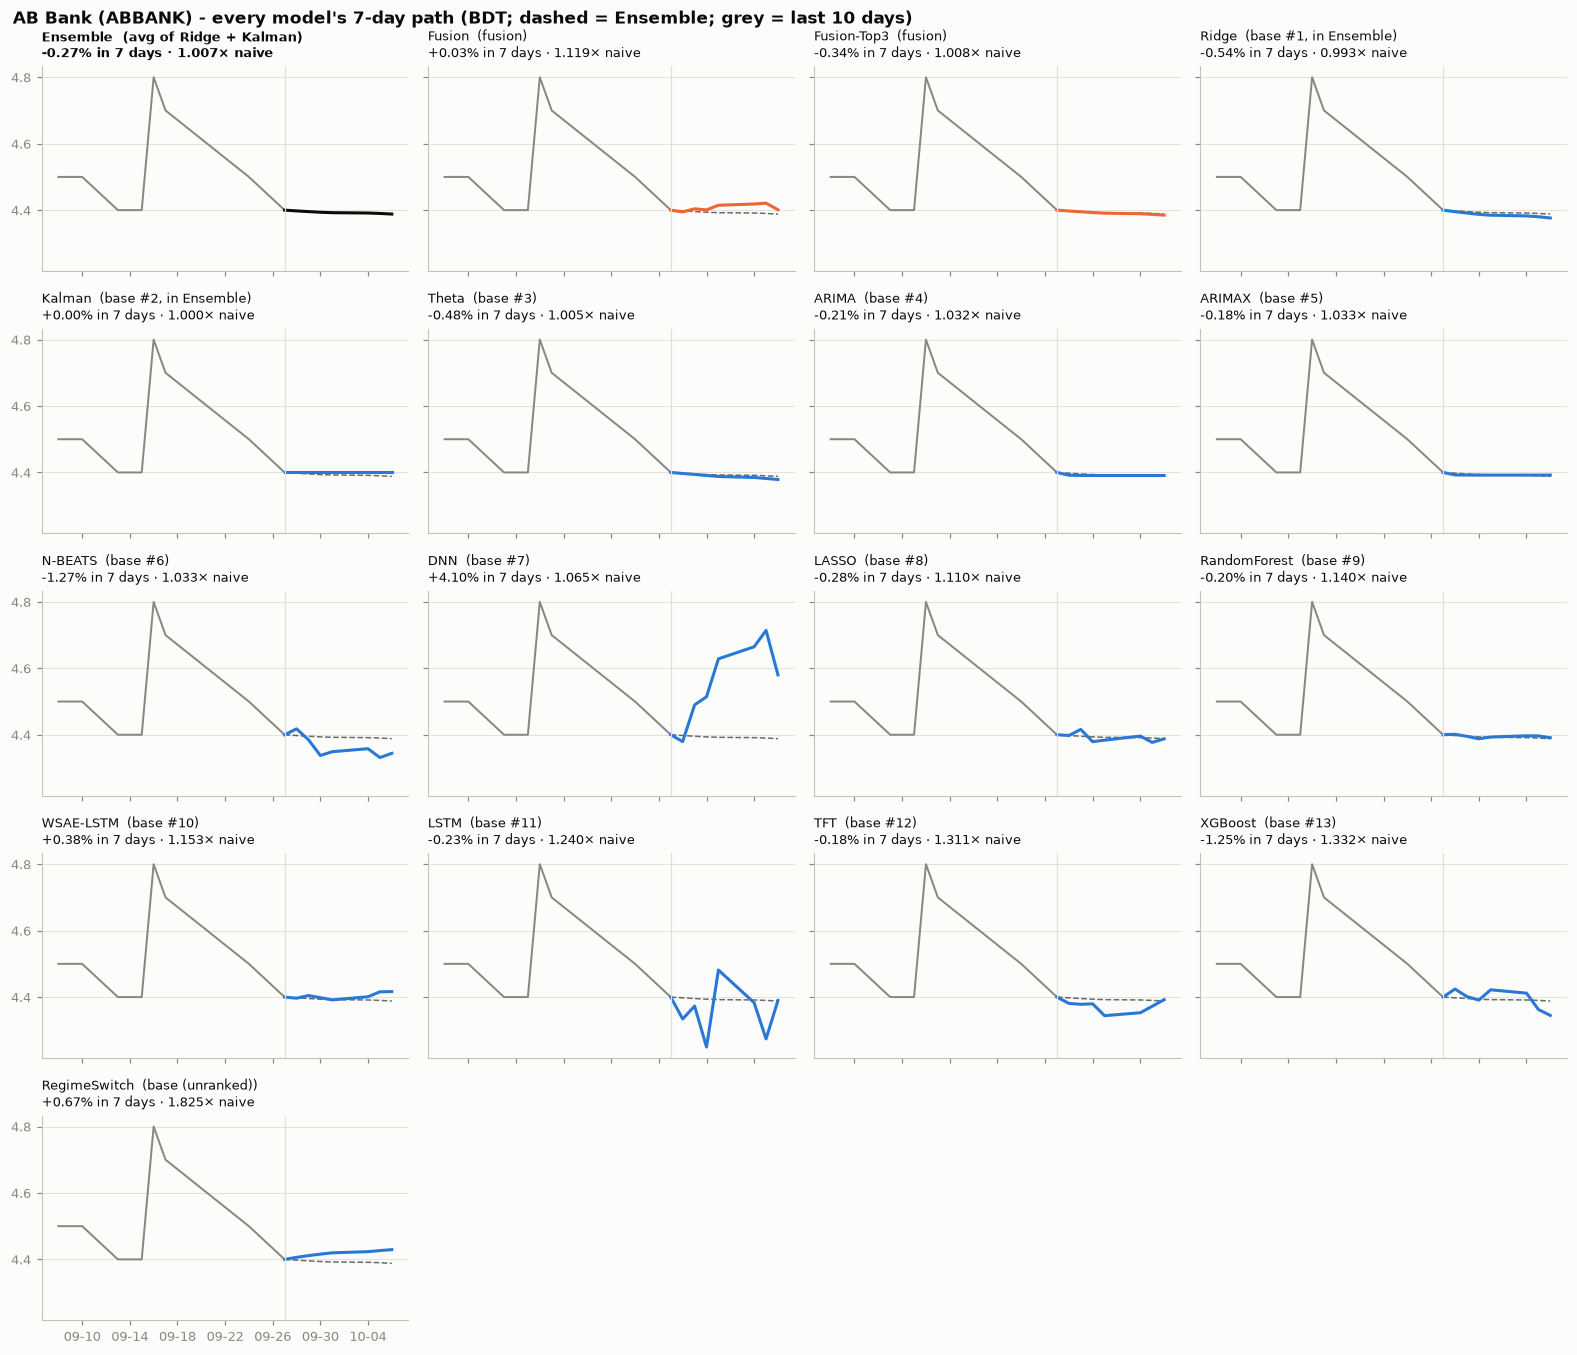

Ensemble = average of the best two models: Ridge + Kalman
Every model's 7-day forecast (BDT); error_vs_naive < 1 beats 'no change':


,role,day1_BDT,day7_BDT,move_7d_%,error_vs_naive,scored_on,holdout_direction_acc
model,,,,,,,
Ensemble,avg of Ridge + Kalman,4.3977,4.3882,-0.27,1.007,unseen test dates,0.301
Fusion,fusion,4.3948,4.4012,0.03,1.119,unseen test dates,0.214
Fusion-Top3,fusion,4.3974,4.3850,-0.34,1.008,unseen test dates,0.301
Ridge,"base #1, in Ensemble",4.3954,4.3764,-0.54,0.993,common holdout,0.397
Kalman,"base #2, in Ensemble",4.4000,4.4000,0.00,1.000,common holdout,0.346
Theta,base #3,4.3970,4.3788,-0.48,1.005,common holdout,0.503
ARIMA,base #4,4.3917,4.3909,-0.21,1.032,common holdout,0.355
ARIMAX,base #5,4.3927,4.3921,-0.18,1.033,common holdout,0.350
N-BEATS,base #6,4.4178,4.3441,-1.27,1.033,common holdout,0.405


Predicted price by day, every model:


,Ridge,XGBoost,LSTM,ARIMA,Kalman,LASSO,RandomForest,DNN,WSAE-LSTM,TFT,Theta,N-BEATS,RegimeSwitch,ARIMAX,Ensemble,Fusion,Fusion-Top3
date,,,,,,,,,,,,,,,,,
2026-09-28,4.3954,4.4243,4.3341,4.3917,4.4,4.3978,4.4014,4.3795,4.3966,4.3810,4.3970,4.4178,4.4061,4.3927,4.3977,4.3948,4.3974
2026-09-29,4.3912,4.4014,4.3731,4.3909,4.4,4.4160,4.3953,4.4899,4.4046,4.3782,4.3939,4.3851,4.4114,4.3921,4.3956,4.4039,4.3951
2026-09-30,4.3872,4.3911,4.2496,4.3909,4.4,4.3792,4.3880,4.5143,4.3981,4.3797,4.3909,4.3377,4.4159,4.3921,4.3936,4.4008,4.3927
2026-10-01,4.3847,4.4220,4.4815,4.3909,4.4,4.3838,4.3933,4.6286,4.3916,4.3440,4.3879,4.3490,4.4198,4.3921,4.3924,4.4146,4.3908
2026-10-04,4.3827,4.4119,4.3831,4.3909,4.4,4.3962,4.3969,4.6649,4.4010,4.3529,4.3848,4.3580,4.4233,4.3921,4.3913,4.4184,4.3892
2026-10-05,4.3800,4.3626,4.2740,4.3909,4.4,4.3770,4.3966,4.7141,4.4158,4.3723,4.3818,4.3314,4.4265,4.3921,4.3900,4.4210,4.3873
2026-10-06,4.3764,4.3448,4.3900,4.3909,4.4,4.3876,4.3911,4.5803,4.4166,4.3923,4.3788,4.3441,4.4294,4.3921,4.3882,4.4012,4.3850


Holdout scoreboard -- every base model on the last 15% of history (mae_vs_naive < 1 beats 'no change'; always-UP would score 24.1% direction):


...

Ensemble, by days ahead:


,graded_calls,hit_within_1pct_%,mean_abs_error_%,direction_calls,direction_hit_%,always_up_%
days_ahead,,,,,,
1,47,36.2,2.02,28,35.7,32.1
2,47,21.3,3.36,38,47.4,26.3
3,47,23.4,4.29,36,47.2,27.8
4,47,25.5,4.54,38,50.0,28.9
5,47,17.0,5.57,40,50.0,40.0
6,47,19.1,6.05,38,47.4,34.2
7,47,14.9,6.73,42,50.0,31.0


Most recent graded Ensemble calls:


,made_on,target_date,days_ahead,price_then,predicted,actual,error_%,within_1pct,direction
0,2026-09-02,2026-09-09,5,4.7,4.69,4.5,4.29,miss,right
1,2026-09-09,2026-09-10,1,4.5,4.50,4.5,0.07,HIT,wrong
2,2026-09-02,2026-09-10,6,4.7,4.69,4.5,4.30,miss,right
3,2026-09-09,2026-09-13,2,4.5,4.49,4.4,2.15,miss,right
4,2026-09-02,2026-09-13,7,4.7,4.69,4.4,6.63,miss,right
5,2026-09-09,2026-09-14,3,4.5,4.49,4.4,2.10,miss,right
6,2026-09-09,2026-09-15,4,4.5,4.49,4.4,2.07,miss,right
7,2026-09-09,2026-09-16,5,4.5,4.49,4.8,6.44,miss,wrong
8,2026-09-09,2026-09-17,6,4.5,4.49,4.7,4.45,miss,wrong
9,2026-09-09,2026-09-24,7,4.5,4.49,4.5,0.24,HIT,wrong


119 call(s) still waiting for their target date (next one: 2026-09-28); 0 fell on a holiday or missing day and can never be graded.


In [1]:
# Forecast Hit Rate -- shared code: raem_analysts/dse/forecast_hit_rate.py
use_shared("forecast_hit_rate")

## 🔮🧐 7-Day Price Forecast Agent + Reviewer Agent (standalone)

Two code-only agents (no Ollama, no earlier cell needed) that sit on top of the 7-day models above and give one answer to *"what will the price be over the next 7 trading days?"*.

**Forecast agent** — takes every base model's error on the common out-of-sample holdout dates, picks the **3 best models for this ticker**, and averages their day+1 ... day+7 paths into one forecast.

**Reviewer agent** — audits that forecast. When a check fails it **changes the forecast** and says what it changed:

- **Data freshness** — warns if the last price is old (the forecast would start from a stale price).
- **Path integrity** — a member with NaN or non-positive prices is replaced by the next best model.
- **Members beat naive** — a member that does not beat "no change" on the holdout is swapped for a better one.
- **Direction agreement** — warns when the 3 models disagree on up/down.
- **Calibration** — if the average is over-confident on the holdout, every move is scaled toward "no change" (only if that cuts the holdout error by 2% or more).
- **Plausible range** — a move bigger than the 95th percentile of past same-horizon moves is clipped.
- **Price band** — a 10-90% range from the models' own holdout errors.
- **Live track record** — the graded hit rate from `forecast_log/`, for context.

The result is a day-by-day price table (the 3 members, the reviewed forecast, low/high), a chart, and a confidence label (HIGH / MEDIUM / LOW). During **Run All** it reuses the forecast trained earlier; run on its own it trains the models first (~2 min). The logic lives in `forecast_agent.py` in the project root.

This is a statistical forecast, not advice: the fusion check table above shows how little most models beat "no change", and LOW confidence means exactly that.

In [ ]:
# ================================================================
# 7-DAY FORECAST AGENT + REVIEWER AGENT -- standalone, run this cell on its own
# ================================================================
import os, sys, warnings
if os.path.abspath("..") not in sys.path:
    sys.path.insert(0, os.path.abspath(".."))

import predictor_lib as pl
import forecast_lib as fl
import forecast_agent as fa

# after the imports: statsmodels re-enables its own warnings when first imported
warnings.filterwarnings("ignore")

AGENT_TICKER = "ABBANK"

# During "Run All" the 7-DAY FORECAST GRAPH cell has already trained every model
# for this ticker -- reuse that instead of training twice.
if isinstance(globals().get("fcast"), dict) and fcast.get("ticker") == AGENT_TICKER:
    print("Reusing the forecast trained earlier in this run.")
else:
    pl.top_up_data_csv(AGENT_TICKER)               # adds finished trading days only
    fcast = fl.forecast_ticker(AGENT_TICKER)       # 14 base models, best-two Ensemble, 2 fusions (~2 min)
    fl.record_forecast(AGENT_TICKER, fcast)        # archived, graded on later runs
    fl.grade_forecasts(AGENT_TICKER)

agent_out = fa.run_forecast_and_review(fcast)      # forecast agent -> reviewer agent -> table + chart
